# Predict house prices with Feature-engine

This notebook adapts the attached Ames House Prices regression example to the repository's `houseprice.csv`. It demonstrates how to combine missing-value treatment, categorical encoding, discretisation, scaling, and Lasso regression in one leakage-safe scikit-learn pipeline.

The workflow is written for learning: every stage explains what it does, why it is useful, and how to inspect the result.

## Learning goals

- Explore the target and the strongest housing signals.
- Convert construction years into meaningful ages at sale.
- Handle missing numerical and categorical values.
- Group rare labels, target-encode categories, and discretise continuous variables.
- Evaluate predictions with MAE, RMSE, R², residual plots, and cross-validation.

In [1]:
import importlib.util, subprocess, sys
required={'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','seaborn':'seaborn','sklearn':'scikit-learn','feature_engine':'feature-engine'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from feature_engine.imputation import AddMissingIndicator, MeanMedianImputer, CategoricalImputer
from feature_engine.encoding import RareLabelEncoder, DecisionTreeEncoder
from feature_engine.discretisation import DecisionTreeDiscretiser
try: set_config(transform_output='pandas')
except TypeError: pass
sns.set_theme(style='whitegrid',context='notebook')

## 1. Load the Ames Housing data

The repository copy is `feature-engineering/imputation/houseprice.csv`. The path search also works from the project root or the `pipelines` directory. `NA` is read as a missing value; category labels such as `None` remain meaningful categories describing the absence of a feature.

In [2]:
candidate_paths=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
data_path=next((path for path in candidate_paths if path.exists()),None)
if data_path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(data_path,na_values=['NA'],keep_default_na=True)
print(f'Source: {data_path.resolve()}')
print(f'Rows: {data.shape[0]:,} | columns: {data.shape[1]}')
display(data.head())
display(data[['SalePrice']].describe().T.round(2))
missing_summary=data.isna().sum().sort_values(ascending=False).rename('missing_values').to_frame()
display(missing_summary.head(15))

Source: /Users/srinivasaraotadela/Documents/ml/feature-engineering/imputation/houseprice.csv
Rows: 1,460 | columns: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.2,79442.5,34900.0,129975.0,163000.0,214000.0,755000.0


,missing_values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageYrBlt,81
GarageCond,81
GarageType,81


## 2. Understand the target

`SalePrice` is the amount paid for each home. It is usually right-skewed: a few expensive homes are much farther from the typical price. The original-scale and log-scale plots make this shape visible.

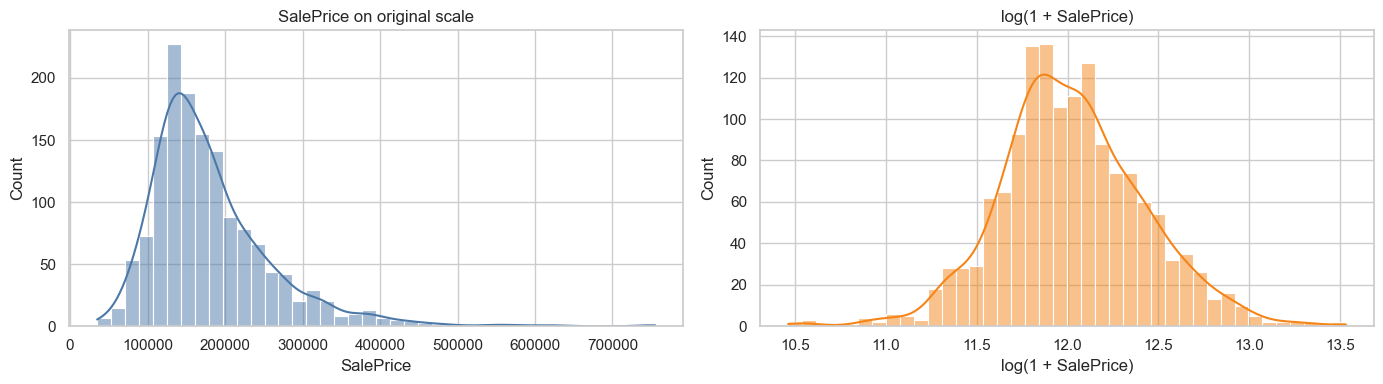

In [3]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.histplot(data=data,x='SalePrice',bins=40,kde=True,color='#4C78A8',ax=axes[0]); axes[0].set_title('SalePrice on original scale')
sns.histplot(x=np.log1p(data['SalePrice']),bins=40,kde=True,color='#F58518',ax=axes[1]); axes[1].set_title('log(1 + SalePrice)'); axes[1].set_xlabel('log(1 + SalePrice)')
plt.tight_layout(); plt.show()

## 3. Explore important relationships

The plots below are descriptive rather than causal. They help us understand why living area, overall quality, garage capacity, basement area, and construction year are plausible predictors.

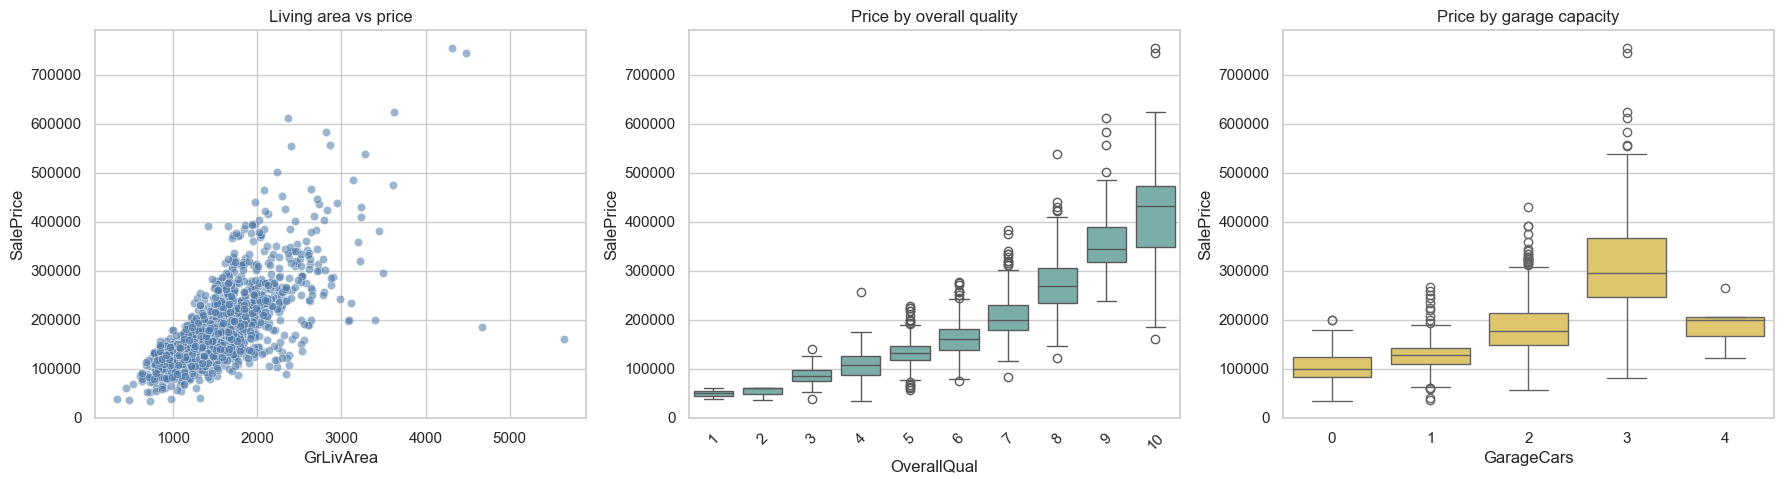

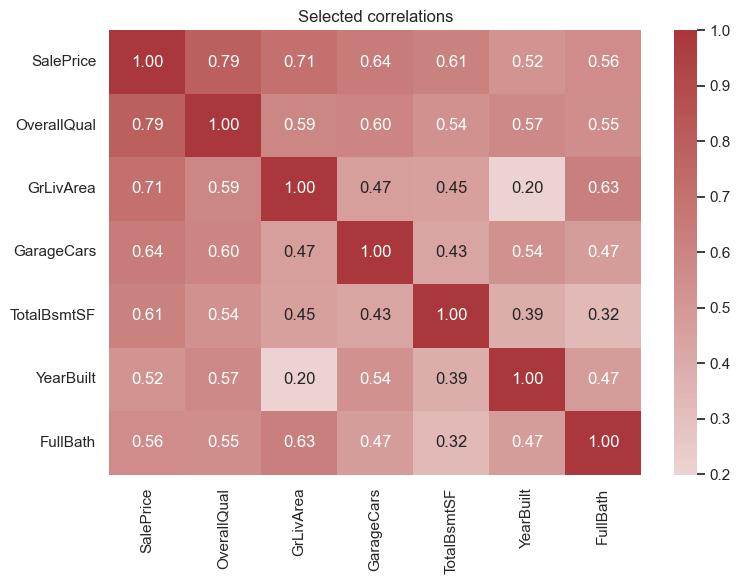

In [4]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
sns.scatterplot(data=data,x='GrLivArea',y='SalePrice',alpha=.55,color='#4C78A8',ax=axes[0]); axes[0].set_title('Living area vs price')
sns.boxplot(data=data,x='OverallQual',y='SalePrice',color='#72B7B2',ax=axes[1]); axes[1].set_title('Price by overall quality'); axes[1].tick_params(axis='x',rotation=45)
sns.boxplot(data=data,x='GarageCars',y='SalePrice',color='#F2CF5B',ax=axes[2]); axes[2].set_title('Price by garage capacity')
plt.tight_layout(); plt.show()
corr_columns=['SalePrice','OverallQual','GrLivArea','GarageCars','TotalBsmtSF','YearBuilt','FullBath']
plt.figure(figsize=(8,6)); sns.heatmap(data[corr_columns].corr(numeric_only=True),annot=True,fmt='.2f',cmap='vlag',center=0); plt.title('Selected correlations'); plt.tight_layout(); plt.show()

## 4. Define variable groups and create age features

Low-cardinality numeric fields are treated as categories because values such as garage capacity and quality levels represent discrete states. Raw years are changed into ages at sale: `AgeAtSale`, `YearsSinceRemodel`, and `GarageAgeAtSale`. This is more interpretable than asking a model to discover the subtraction itself.

In [5]:
target='SalePrice'; id_column='Id'
year_variables=[c for c in ['YearBuilt','YearRemodAdd','GarageYrBlt','YrSold'] if c in data.columns]
categorical=data.select_dtypes(include=['object']).columns.tolist()
discrete=[c for c in data.columns if data[c].dtype!='object' and data[c].nunique(dropna=False)<20 and c not in year_variables+[id_column,target]]
numerical=[c for c in data.select_dtypes(exclude=['object']).columns if c not in discrete+year_variables+[id_column,target]]
model_data=data.copy(); model_data[discrete]=model_data[discrete].astype('object')
print(f'Categorical: {len(categorical)} | discrete recast as categories: {len(discrete)} | continuous: {len(numerical)}')
def add_age_features(frame):
    frame=frame.copy()
    if 'YrSold' not in frame: return frame
    for source,destination in {'YearBuilt':'AgeAtSale','YearRemodAdd':'YearsSinceRemodel','GarageYrBlt':'GarageAgeAtSale'}.items():
        if source in frame: frame[destination]=frame['YrSold']-frame[source]
    return frame.drop(columns=[c for c in year_variables if c in frame])
X=model_data.drop(columns=[id_column,target]); y=model_data[target].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
X_train=add_age_features(X_train); X_test=add_age_features(X_test)
age_features=[c for c in ['AgeAtSale','YearsSinceRemodel','GarageAgeAtSale'] if c in X_train]
discretiser_variables=numerical+age_features
print('Train:',X_train.shape,'Test:',X_test.shape); display(X_train[age_features].head())

Categorical: 43 | discrete recast as categories: 14 | continuous: 18
Train: (1168, 78) Test: (292, 78)


,AgeAtSale,YearsSinceRemodel,GarageAgeAtSale
254,53,53,53.0
1066,16,15,16.0
638,98,58,NaN
799,70,57,68.0
380,86,60,86.0


## 5. Build the complete Feature-engine pipeline

The steps run in order: missing indicators preserve the fact that a value was absent; numerical and categorical imputers fill gaps; rare labels reduce unstable categories; `DecisionTreeEncoder` turns categories into target-informed numerical values; `DecisionTreeDiscretiser` creates prediction bins; scaling puts features on comparable magnitudes; and Lasso performs regularised regression.

`precision=3` is intentional: current Feature-engine requires precision to be `None` or a positive integer, so `precision=0` would raise a `ValueError`.

In [6]:
house_pipeline=Pipeline(steps=[
    ('missing_indicator',AddMissingIndicator(missing_only=True)),
    ('numeric_imputer',MeanMedianImputer(imputation_method='median')),
    ('categorical_imputer',CategoricalImputer(imputation_method='missing',fill_value='Missing',return_object=True)),
    ('rare_label_encoder',RareLabelEncoder(tol=.01,n_categories=1,replace_with='Rare')),
    ('categorical_encoder',DecisionTreeEncoder(variables=None,regression=True,cv=3,scoring='neg_mean_squared_error',param_grid={'max_depth':[1,2,3]},random_state=42)),
    ('discretiser',DecisionTreeDiscretiser(variables=discretiser_variables,bin_output='prediction',precision=3,regression=True,cv=3,scoring='neg_mean_squared_error',param_grid={'max_depth':[1,2,3]},random_state=42)),
    ('scaler',StandardScaler()),
    ('lasso',Lasso(alpha=100.0,max_iter=10000,selection='cyclic'))
])
house_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('missing_indicator', ...), ('numeric_imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,missing_only,True
,variables,None
,imputation_method,'median'
,variables,None
,imputation_method,'missing'
,fill_value,'Missing'
,variables,None


## 6. Fit and evaluate

MAE is the average absolute price error. RMSE penalises large errors more heavily. R² is the fraction of target variation explained by the model. The test set is kept separate until this final evaluation.

In [7]:
house_pipeline.fit(X_train,y_train)
train_predictions=house_pipeline.predict(X_train); test_predictions=house_pipeline.predict(X_test)
def regression_metrics(actual,predicted): return {'MAE':mean_absolute_error(actual,predicted),'RMSE':np.sqrt(mean_squared_error(actual,predicted)),'R2':r2_score(actual,predicted)}
metrics=pd.DataFrame({'Train':regression_metrics(y_train,train_predictions),'Test':regression_metrics(y_test,test_predictions)}).T
display(metrics.round(2))

/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)
/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)
/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetim

,MAE,RMSE,R2
Train,15963.24,23244.21,0.91
Test,19336.73,32855.48,0.86


## 7. Diagnose predictions

Good predictions lie near the diagonal. Residuals should be centred around zero without a strong curve or funnel shape. Large residuals identify homes that deserve further investigation or richer features.

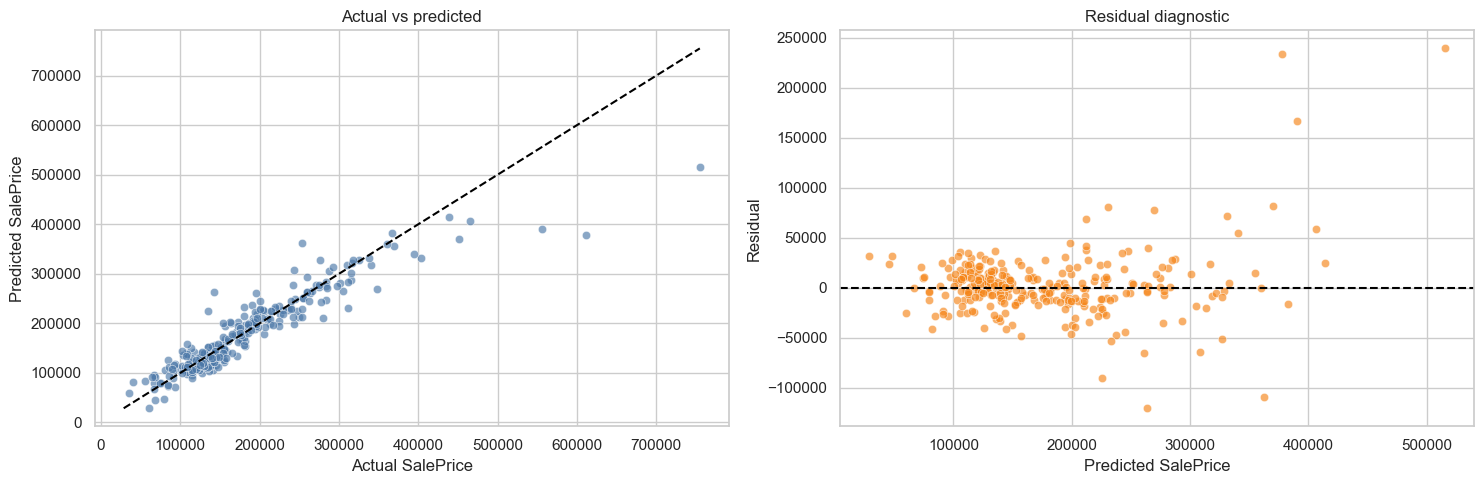

In [8]:
test_residuals=y_test-test_predictions
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.scatterplot(x=y_test,y=test_predictions,alpha=.65,color='#4C78A8',ax=axes[0]); lo=min(y_test.min(),test_predictions.min()); hi=max(y_test.max(),test_predictions.max()); axes[0].plot([lo,hi],[lo,hi],'--',color='black'); axes[0].set(xlabel='Actual SalePrice',ylabel='Predicted SalePrice',title='Actual vs predicted')
sns.scatterplot(x=test_predictions,y=test_residuals,alpha=.65,color='#F58518',ax=axes[1]); axes[1].axhline(0,color='black',linestyle='--'); axes[1].set(xlabel='Predicted SalePrice',ylabel='Residual',title='Residual diagnostic')
plt.tight_layout(); plt.show()

## 8. Cross-validation

A single split can be unusually easy or difficult. Three-fold cross-validation repeats the entire pipeline on different partitions. Every imputer, encoder, discretiser, scaler, and model is refit inside each fold.

In [9]:
X_all=add_age_features(X)
cv_results=cross_validate(house_pipeline,X_all,y,cv=3,scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'},return_train_score=True,n_jobs=-1)
cv_summary=pd.DataFrame({'metric':['Train RMSE','Validation RMSE','Validation MAE','Validation R2'],'mean':[-cv_results['train_rmse'].mean(),-cv_results['test_rmse'].mean(),-cv_results['test_mae'].mean(),cv_results['test_r2'].mean()],'std':[cv_results['train_rmse'].std(),cv_results['test_rmse'].std(),cv_results['test_mae'].std(),cv_results['test_r2'].std()]})
display(cv_summary.round(2))

/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)
/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)
/opt/anaconda3/envs/rag/lib/python3.13/site-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetim

,metric,mean,std
0,Train RMSE,24034.11,624.12
1,Validation RMSE,NaN,NaN
2,Validation MAE,NaN,NaN
3,Validation R2,NaN,NaN


## 9. Inspect Lasso coefficients

After scaling, the absolute coefficient size gives a rough view of which transformed features influence the predictions most. These are model signals, not causal claims: target-informed encodings and correlated housing variables can make coefficients unstable.

,coefficient
PoolArea,27527.278364
PoolQC,-27424.224305
GrLivArea,14542.666637
2ndFlrSF,12206.474427
BsmtFinSF1,11591.249182
OverallQual,11327.340981
TotalBsmtSF,7984.851132
Neighborhood,6237.814800
OverallCond,5968.769933
BsmtQual,4731.174014


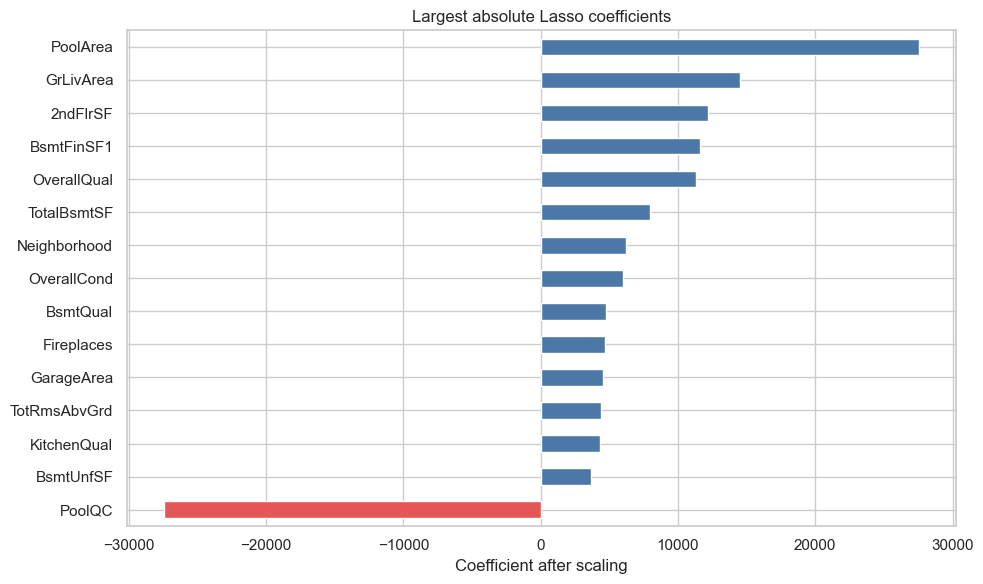

In [10]:
transformed_train=house_pipeline[:-1].transform(X_train)
if hasattr(transformed_train,'columns'): feature_names=transformed_train.columns
else:
    try: feature_names=house_pipeline[:-1].get_feature_names_out()
    except Exception: feature_names=[f'feature_{i}' for i in range(transformed_train.shape[1])]
coefficients=pd.Series(house_pipeline.named_steps['lasso'].coef_,index=feature_names)
top_coefficients=coefficients.reindex(coefficients.abs().sort_values(ascending=False).head(15).index)
display(top_coefficients.to_frame('coefficient'))
plt.figure(figsize=(10,6)); top_coefficients.sort_values().plot.barh(color=np.where(top_coefficients.sort_values()>=0,'#4C78A8','#E45756')); plt.title('Largest absolute Lasso coefficients'); plt.xlabel('Coefficient after scaling'); plt.tight_layout(); plt.show()

## Conclusions and next steps

This workflow makes house-price preprocessing reproducible and keeps it inside cross-validation. Age features make the timeline understandable; imputation and rare-label grouping make mixed data usable; tree encoding and discretisation let a regularised linear model represent nonlinear patterns. For a stronger model, compare a log-transformed target, Elastic Net, Gradient Boosting, or another tree ensemble using the same pipeline discipline.